# Leemos datos de manera cruda
Leemos los datos del cvs Puntos de calor que son datos crudos de incendios forestales mas que todo en el amazonas


In [70]:
import pandas as pd

df = pd.read_csv('../PuntosCalor.csv',
                sep= ',',
                encoding= 'utf-8',
                decimal= '.',
                na_values=["", "NA", "N/A", "-", "null", "999"],
                skipinitialspace=True)


print(df.shape)
print(df.info())
print(df.head())
print(df.describe(include="all"))




C:\Users\Cristian\AppData\Local\Temp\ipykernel_10688\3574685621.py:3: DtypeWarning: Columns (16) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../PuntosCalor.csv',


(447213, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 447213 entries, 0 to 447212
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   X                 447213 non-null  float64
 1   Y                 447213 non-null  float64
 2   objectid          447213 non-null  int64  
 3   latitude          447213 non-null  float64
 4   longitude         447213 non-null  float64
 5   acq_date          447213 non-null  object 
 6   instrument        447213 non-null  object 
 7   fecha_date        447213 non-null  object 
 8   paisaje           447213 non-null  object 
 9   departamen        447213 non-null  object 
 10  municipio         447213 non-null  object 
 11  car               447213 non-null  object 
 12  sigla_elt         447212 non-null  object 
 13  leyenda           447213 non-null  object 
 14  acq_col           447213 non-null  object 
 15  confidence_modis  3131 non-null    float64
 16  confide

# Parseo de datos
Interpretamos datos crudos 

In [71]:
#Numericos
df["X"] = pd.to_numeric(df["X"], errors="coerce")
df["Y"] = pd.to_numeric(df["Y"], errors="coerce")
df["objectid"] = pd.to_numeric(df["objectid"], errors="coerce")
df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")
#Fecha
df["fecha_date"] = pd.to_datetime(df["fecha_date"], errors="coerce", dayfirst=True)
df["acq_date"] = pd.to_datetime(df["acq_date"], errors="coerce", dayfirst=True)
#Texto
df["departamen"] = df["departamen"].astype(str).str.strip().str.upper()
df["municipio"] = df["municipio"].astype(str).str.strip().str.upper()
df["paisaje"] = df["paisaje"].astype(str).str.strip().str.lower()
df["car"] = df["car"].astype(str).str.strip().str.lower()
df["leyenda"] = df["leyenda"].astype(str).str.strip().str.lower()


perdidosX = df["X"].isna().sum()
perdidosY = df["Y"].isna().sum()
perdidosObjectid = df["objectid"].isna().sum()
perdidosLatitude = df["latitude"].isna().sum()
perdidosLongitude = df["longitude"].isna().sum()
perdidosFecha = df["fecha_date"].isna().sum()
perdidosAcqDate = df["acq_date"].isna().sum()
perdidosDepartamento = df["departamen"].isna().sum()
perdidosMunicipio = df["municipio"].isna().sum()
perdidosPaisaje = df["paisaje"].isna().sum()
perdidosCar = df["car"].isna().sum()
perdidosLeyenda = df["leyenda"].isna().sum()



C:\Users\Cristian\AppData\Local\Temp\ipykernel_10688\2084924522.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["fecha_date"] = pd.to_datetime(df["fecha_date"], errors="coerce", dayfirst=True)
C:\Users\Cristian\AppData\Local\Temp\ipykernel_10688\2084924522.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["acq_date"] = pd.to_datetime(df["acq_date"], errors="coerce", dayfirst=True)


# Depuración de datos
Depuramos los datos pareados para eliminar duplicidad, consistencia y rangos posibles

In [72]:
reporte = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_faltantes": df.isna().sum(),
    "pct_faltantes": df.isna().mean() * 100,
    "n_unicos": df.nunique(dropna=False),
})
df = df.drop_duplicates(keep="first")  # solo para copias exactas
print(reporte)
print("filas duplicadas:", df.duplicated().sum())

                                dtype  n_faltantes  pct_faltantes  n_unicos
X                             float64            0       0.000000    260955
Y                             float64            0       0.000000    242901
objectid                        int64            0       0.000000    447213
latitude                      float64            0       0.000000    241812
longitude                     float64            0       0.000000    260895
acq_date          datetime64[ns, UTC]            0       0.000000      2962
instrument                     object            0       0.000000         3
fecha_date        datetime64[ns, UTC]            0       0.000000      3132
paisaje                        object            0       0.000000         2
departamen                     object            0       0.000000        10
municipio                      object            0       0.000000        70
car                            object            0       0.000000         6
sigla_elt   

# Imputamos
NaN

In [73]:
df = df.dropna(how="all")
umbral = 0.40
columnas_utiles = df.columns[df.isna().mean() < umbral]

for col in ["X", "Y", "objectid", "latitude", "longitude", "confidence_modis"]:
    if col in df.columns:
        mediana = df[col].median()
        df[col] = df[col].fillna(mediana)

for col in ["acq_date", "fecha_date", "acq_col"]:
    if col in df.columns:
        moda_fecha = df[col].mode()
        if not moda_fecha.empty:
            df[col] = df[col].fillna(moda_fecha.iloc[0])

for col in ["instrument", "paisaje", "departamen", "municipio", "car", "sigla_elt", "leyenda", "confidence"]:
    if col in df.columns:
        moda = df[col].mode()
        if not moda.empty:
            df[col] = df[col].fillna(moda.iloc[0])

print(df.isna().sum())
print(df.head())


X                   0
Y                   0
objectid            0
latitude            0
longitude           0
acq_date            0
instrument          0
fecha_date          0
paisaje             0
departamen          0
municipio           0
car                 0
sigla_elt           0
leyenda             0
acq_col             0
confidence_modis    0
confidence          0
dtype: int64
              X            Y  objectid  latitude  longitude  \
0 -7.799377e+06 -332996.4539     66533    -2.990    -70.063   
1 -7.779897e+06 -321738.3709     66534    -2.889    -69.888   
2 -8.005430e+06 -249419.2049     66535    -2.240    -71.914   
3 -8.090367e+06 -171898.1001     66536    -1.544    -72.677   
4 -8.089587e+06 -168334.6092     66537    -1.512    -72.670   

                   acq_date instrument                fecha_date  paisaje  \
0 2014-10-01 06:00:00+00:00      MODIS 2014-10-01 14:00:00+00:00  llanura   
1 2014-11-11 06:00:00+00:00      MODIS 2014-11-11 14:00:00+00:00  llanura   
2 2

In [ ]:
%pip install matplotlib seaborn



[notice] A new release of pip available: 22.2.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



  Using cached matplotlib-3.10.9-cp310-cp310-win_amd64.whl (8.2 MB)
  Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
  Using cached fonttools-4.63.0-cp310-cp310-win_amd64.whl (1.6 MB)
  Using cached contourpy-1.3.2-cp310-cp310-win_amd64.whl (221 kB)
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
  Using cached kiwisolver-1.5.1-cp310-cp310-win_amd64.whl (70 kB)


C:\Users\Cristian\AppData\Local\Temp\ipykernel_10688\1124414654.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


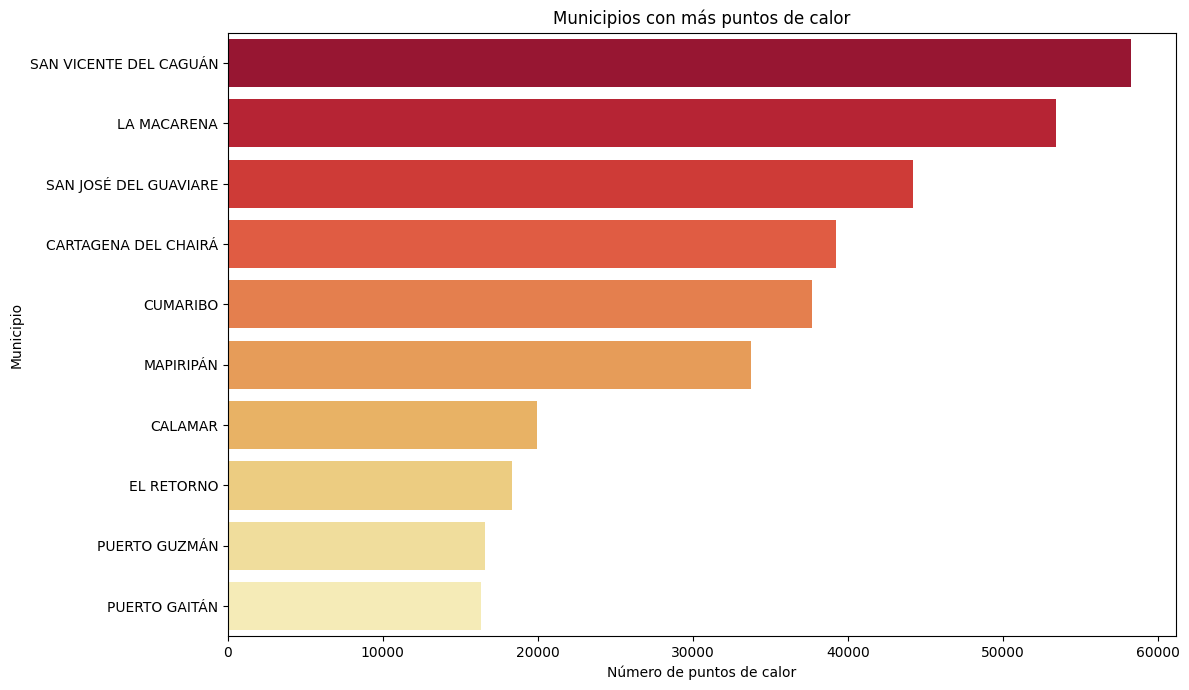

                 municipio  puntos_calor
56  SAN VICENTE DEL CAGUÁN         58257
18             LA MACARENA         53447
52   SAN JOSÉ DEL GUAVIARE         44205
5     CARTAGENA DEL CHAIRÁ         39243
7                 CUMARIBO         37717
23               MAPIRIPÁN         33768
4                  CALAMAR         19966
12              EL RETORNO         18336
46           PUERTO GUZMÁN         16577
45           PUERTO GAITÁN         16332


In [84]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Aseguramos formato de fecha
if "acq_date" in df.columns:
    df["acq_date"] = pd.to_datetime(df["acq_date"], errors="coerce")

# Filtramos solo datos geográficamente válidos para Colombia
lat_min, lat_max = -4.23, 12.5
lon_min, lon_max = -81.4, -66.8

mask = (
    df["latitude"].between(lat_min, lat_max) &
    df["longitude"].between(lon_min, lon_max)
)

df_col = df[mask].copy()

# Conteo total por municipio
conteo_municipio = (
    df_col.groupby("municipio", dropna=False)
    .size()
    .reset_index(name="puntos_calor")
    .sort_values("puntos_calor", ascending=False)
)

# Top 10 para que se vea clara
conteo_top = conteo_municipio.head(10)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=conteo_top,
    x="puntos_calor",
    y="municipio",
    palette="YlOrRd_r",
    orient="h"
)
plt.title("Municipios con más puntos de calor")
plt.xlabel("Número de puntos de calor")
plt.ylabel("Municipio")
plt.tight_layout()
plt.show()

print(conteo_top)

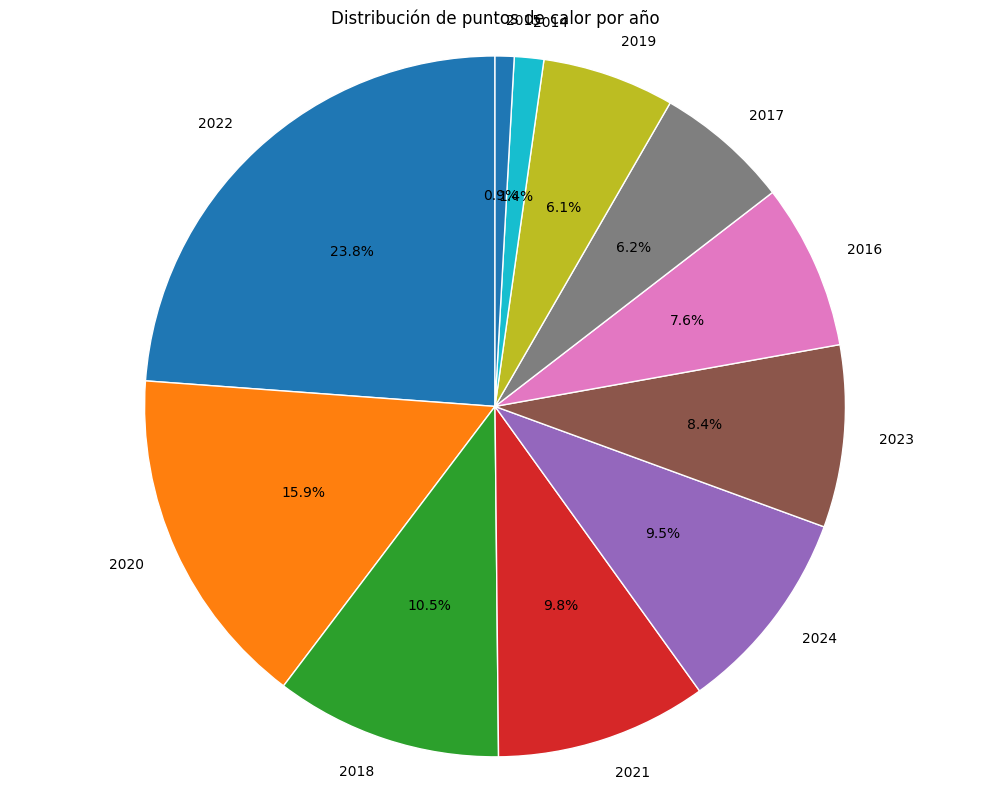

    anio  puntos_calor
8   2022        106608
6   2020         70893
4   2018         46825
7   2021         43651
10  2024         42466
9   2023         37595
2   2016         34129
3   2017         27791
5   2019         27268
0   2014          6068
1   2015          3919


In [80]:
if "acq_date" in df.columns:
    df["acq_date"] = pd.to_datetime(df["acq_date"], errors="coerce")

# Filtrar lat/lon válidas de Colombia
lat_min, lat_max = -4.23, 12.5
lon_min, lon_max = -81.4, -66.8
mask = (
    df["latitude"].between(lat_min, lat_max) &
    df["longitude"].between(lon_min, lon_max)
)

df_col = df[mask].copy()

# Conteo por año
conteo_anio = (
    df_col.groupby(df_col["acq_date"].dt.year)
    .size()
    .reset_index(name="puntos_calor")
    .rename(columns={"acq_date": "anio"})
    .sort_values("puntos_calor", ascending=False)
)

# Graficar pastel
plt.figure(figsize=(10, 8))
labels = conteo_anio["anio"].astype(str)
values = conteo_anio["puntos_calor"]

plt.pie(
    values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 1}
)
plt.title("Distribución de puntos de calor por año")
plt.axis("equal")
plt.tight_layout()
plt.show()

print(conteo_anio)


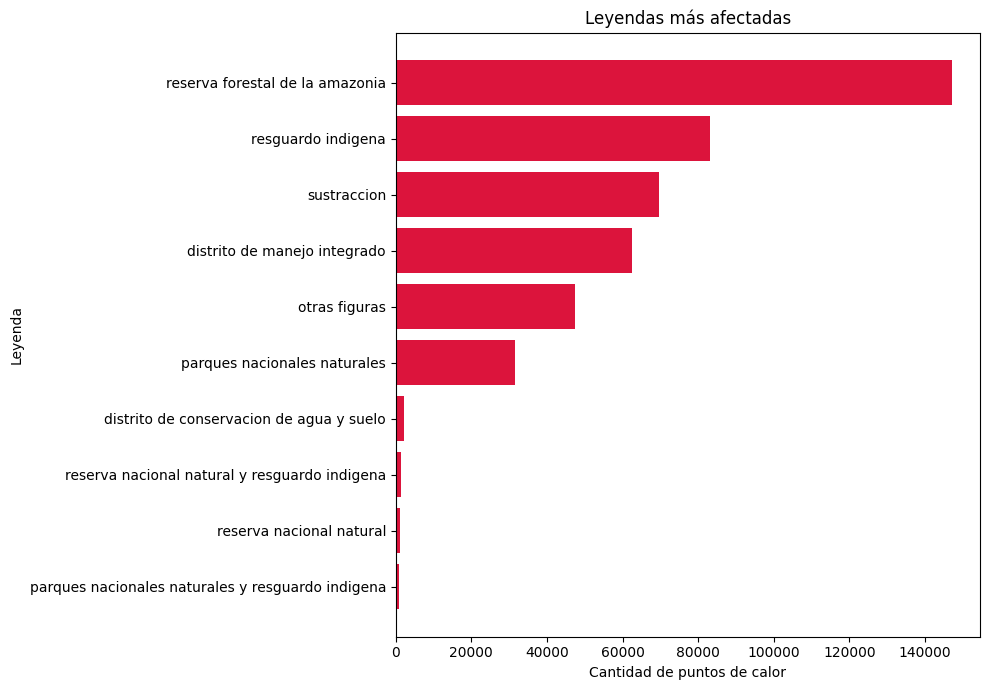

                                             leyenda  cantidad
0                    reserva forestal de la amazonia    147229
1                                 resguardo indigena     83233
2                                        sustraccion     69640
3                       distrito de manejo integrado     62594
4                                      otras figuras     47492
5                       parques nacionales naturales     31446
6           distrito de conservacion de agua y suelo      2117
7      reserva nacional natural y resguardo indigena      1300
8                           reserva nacional natural      1208
9  parques nacionales naturales y resguardo indigena       769


In [85]:
import pandas as pd
import matplotlib.pyplot as plt

# Filtrar solo Colombia
lat_min, lat_max = -4.23, 12.5
lon_min, lon_max = -81.4, -66.8
mask = (
    df["latitude"].between(lat_min, lat_max) &
    df["longitude"].between(lon_min, lon_max)
)
df_col = df[mask].copy()

# Conteo de leyendas más afectadas
conteo_leyendas = (
    df_col["leyenda"].fillna("Sin información")
    .value_counts()
    .head(10)
    .reset_index()
)
conteo_leyendas.columns = ["leyenda", "cantidad"]

# Gráfica de barras
plt.figure(figsize=(10, 7))
plt.barh(conteo_leyendas["leyenda"][::-1], conteo_leyendas["cantidad"][::-1], color="crimson")
plt.title("Leyendas más afectadas")
plt.xlabel("Cantidad de puntos de calor")
plt.ylabel("Leyenda")
plt.tight_layout()
plt.show()

print(conteo_leyendas)
